In [9]:
#first lets determine interannual variability to determine downscaling vs climatology prediction

# Purpose: Determine the native spatial skill of the RF precipitation model
# across output resolutions from 1 to 6 km.

# For each resolution the full pipeline runs end-to-end:
#   Section 3 — Resample existing 1km monthly rasters to target resolution
#   Section 4 — Build train + test feature matrices at target resolution
#   Section 5 — Fit and tune global RF (RandomizedSearchCV, 5-fold CV)
#   Section 6 — Predict full monthly rasters at target resolution (optional)
#   Section 7 — Compare R², RMSE, pbias across all resolutions - CHANGE THIS
#
# Source data: 1km monthly rasters already produced by monthly_raster_aggregation.
# No raw daily files are re-read — all resampling is from the 1km outputs.
# 1km uses source rasters directly (no resampling).
#
# OUTPUT FOLDER: ..\Data\Processed\Resolution_Skill_Test\
#   Each resolution writes to its own subfolder (1km/, 2km/, ... 6km/)
#   Final comparison table and plot are written to the root folder.
# =============================================================================

In [10]:
import os
import gc
import glob
import shutil
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import joblib
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [11]:
# Date range 
START_YEAR, START_MONTH = 2001, 1
END_YEAR,   END_MONTH   = 2005, 12
 
# Resolutions to test (km) 
RESOLUTIONS = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6]

TEMPLATE_PATHS = {
    1: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1km.tif",
    1.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1_5km.tif",
    2: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2km.tif",
    2.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2_5km.tif",   
    3: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3km.tif",
    3.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3_5km.tif",     
    4: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4km.tif",
    4.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4_5km.tif",   
    5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5km.tif",
    5.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5_5km.tif",   
    6: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_6km.tif"   
    }
 
SOURCE_RASTER_1KM = r"..\Data\Processed\RegressionModel\Monthly_Rasters"

STATIC_PATHS_1KM = {
    "cluster":          r"..\Data\Processed\Spatial_clustering\Precipitation_clusters.tif",
    "elev_mean":        r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_mean.tif",
    "elev_std":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_std.tif",
    "elev_max":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif",
    "elev_min":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_min.tif",
    "slope_mean":       r"..\Data\Datasets\DEM_1km\DEM_1km_slope_mean.tif",
    "aspect_mean":      r"..\Data\Datasets\DEM_1km\DEM_1km_aspect_mean.tif",
    "elev_smoothed":    r"..\Data\Processed\Fetch\Preprocessing\dem_smoothed.tif",
    "fetch_1000m_dist": r"..\Data\Processed\Fetch\Preprocessing\fetch_dist_1000m.tif",
    "fetch_1000m_dir":  r"..\Data\Processed\Fetch\Preprocessing\fetch_dir_1000m.tif",
    "fetch_500m_dist":  r"..\Data\Processed\Fetch\Preprocessing\fetch_dist_500m.tif",
    "fetch_500m_dir":   r"..\Data\Processed\Fetch\Preprocessing\fetch_dir_500m.tif",
    "local_relief":     r"..\Data\Processed\Fetch\Preprocessing\local_relief.tif",
}

# In-situ data 
INSITU_CSV     = r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv"
TRAIN_STATIONS = r"..\Data\Processed\Split_stations\train_stations.csv"
TEST_STATIONS  = r"..\Data\Processed\Split_stations\test_stations.csv"
 
# Output root (all resolution subfolders created here)
OUT_ROOT = r"..\Data\Processed\Resolution_Skill_Test"
 
# Model and pipeline settings
MIN_VALID_DAYS    = 20    
RANDOM_STATE      = 64
N_CORES           = 2
N_ITER_SEARCH     = 50      
CV_FOLDS          = 5
TARGET_VAR        = "insitu_monthly_total"

PREDICTOR_FEATURES = [
    'y', 'x',
    'era5l_monthly_sum', 'chirps_monthly_sum', 'har_monthly_sum',
    'persiann_monthly_sum', 'mswep_monthly_sum',
    'chirps_wet_day_count', 'chirps_monthly_std',
    'evi_monthly_mean', 'lst_d_monthly_mean', 'lst_d_missing_fraction',
    'lst_n_monthly_mean', 'lst_n_missing_fraction', 'lst_diff_monthly_mean',
    'cluster', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean',
    'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
    'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'month_sin', 'month_cos'
]
 
RUN_PREDICTION_RASTERS = True

os.makedirs(OUT_ROOT, exist_ok=True)
 
month_range = pd.period_range(
    start=f"{START_YEAR}-{START_MONTH:02d}",
    end=f"{END_YEAR}-{END_MONTH:02d}",
    freq="M"
)

In [12]:
# SECTION 1 — Helper functions
 
def mlabel(year: int, month: int) -> str:
    """YYYYMM string used in all filenames."""
    return f"{year}{month:02d}"
 
 
def month_cyclical(month: int):
    """Cyclical (sin, cos) encoding for calendar months 1–12."""
    angle = 2 * np.pi * month / 12
    return np.sin(angle), np.cos(angle)
 
 
def kd_threshold(res_km: int) -> float:
    """
    KD-tree matching distance threshold in degrees.
    0.006° at 1km ≈ one pixel radius; scales linearly with resolution.
    Prevents stations just off a pixel centroid from being excluded when
    the grid is coarser.
    """
    return 0.006 * res_km
 
 
def res_paths(res_km: int) -> dict:
    """
    Centralised path dictionary for a given resolution.
    All other sections reference paths from here — nothing is hard-coded elsewhere.
    """
    base = os.path.join(OUT_ROOT, f"{res_km}km")
    return {
        "base":           base,
        "rasters":        os.path.join(base, "Monthly_Rasters"),
        "static_csv":     os.path.join(base, "static_df.csv"),
        "monthly_train":  os.path.join(base, "monthly_train_csv"),
        "monthly_test":   os.path.join(base, "monthly_test_csv"),
        "monthly_pred":   os.path.join(base, "monthly_pred_csv"),
        "train_parquet":  os.path.join(base, "train_df.parquet"),
        "test_parquet":   os.path.join(base, "test_df.parquet"),
        "model":          os.path.join(base, "rf_model.pkl"),
        "pred_rasters":   os.path.join(base, "Predicted_Rasters"),
        "metrics":        os.path.join(base, "metrics.csv"),
    }
 
 
def monthly_raster_paths(year: int, month: int, raster_dir: str) -> dict:
    """
    Map {feature_name: filepath} for all monthly rasters for a given
    year-month in raster_dir. Mirrors build_monthly_paths() from main pipeline.
    Both dynamic (precipitation, LST, EVI) and their diagnostic derivatives
    are included. Missing files are handled downstream with NaN fill.
    """
    L = mlabel(year, month)
    R = raster_dir
    return {
        "era5l_monthly_sum":         f"{R}/era5l/era5l_monthly_sum_{L}.tif",
        "chirps_monthly_sum":        f"{R}/chirps/chirps_monthly_sum_{L}.tif",
        "har_monthly_sum":           f"{R}/har/har_monthly_sum_{L}.tif",
        "persiann_monthly_sum":      f"{R}/persiann/persiann_monthly_sum_{L}.tif",
        "mswep_monthly_sum":         f"{R}/mswep/mswep_monthly_sum_{L}.tif",
        "chirps_wet_day_count":      f"{R}/chirps/chirps_wet_day_count_{L}.tif",
        "chirps_monthly_std":        f"{R}/chirps/chirps_monthly_std_{L}.tif",
        "evi_monthly_mean":          f"{R}/modis_evi/evi_monthly_mean_{L}.tif",
        "evi_missing_fraction":      f"{R}/modis_evi/evi_missing_fraction_{L}.tif",
        "lst_d_monthly_mean":        f"{R}/modis_lst/lst_d_monthly_mean_{L}.tif",
        "lst_d_missing_fraction":    f"{R}/modis_lst/lst_d_missing_fraction_{L}.tif",
        "lst_n_monthly_mean":        f"{R}/modis_lst/lst_n_monthly_mean_{L}.tif",
        "lst_n_missing_fraction":    f"{R}/modis_lst/lst_n_missing_fraction_{L}.tif",
        "lst_diff_monthly_mean":     f"{R}/modis_lst/lst_diff_monthly_mean_{L}.tif",
        "lst_diff_missing_fraction": f"{R}/modis_lst/lst_diff_missing_fraction_{L}.tif",
    }
 
def compute_metrics(y_true, y_pred):
    """Return a dict of accuracy metrics for a single split."""
    residuals = y_pred - y_true

    # Basic metrics
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    n    = len(y_true)

    # Percent bias  (same formula as your reference snippet)
    pbias = 100 * np.sum(y_pred - y_true) / np.sum(y_true)

    # Spearman correlation  (scipy — no extra dependency needed)
    from scipy.stats import spearmanr
    correlation, _ = spearmanr(y_pred, y_true)

    # NRMSE — normalised by the mean of observations
    nrmse = rmse / np.mean(y_true) if np.mean(y_true) != 0 else np.nan

    # Relative Standard Deviation  (std of predictions / std of observations)
    rsd = np.std(y_pred) / np.std(y_true) if np.std(y_true) != 0 else np.nan

    return {
        "r2":          r2,
        "rmse":        rmse,
        "pbias":       pbias,
        "correlation": correlation,
        "nrmse":       nrmse,
        "rsd":         rsd,
        "n":           n,
    }
 
def get_rf_param_grid() -> dict:
    """RandomizedSearchCV hyperparameter grid — same as main pipeline."""
    return {
        'reg__n_estimators':      [50, 100, 500, 1000, 2000],
        'reg__max_features':      ['sqrt', 'log2'],
        'reg__max_depth':         [None, 10, 20, 30],
        'reg__min_samples_split': [2, 5, 10],
        'reg__min_samples_leaf':  [1, 2, 4],
    }
 
def load_rasters_to_grid(paths: dict, template: xr.DataArray) -> tuple:
    """
    Load a {name: filepath} dict, resample each to template, merge to a
    pixel DataFrame. Returns (dynamic_df, missing_vars).
    Columns = raster names; rows = one per pixel.
    """
    aligned, missing_vars = [], []
    for name, path in paths.items():
        if not os.path.exists(path):
            missing_vars.append(name)
            continue
        da = rxr.open_rasterio(path, masked=True).rio.write_crs("EPSG:4326")
        da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
        if "band" in da.dims and da.sizes["band"] == 1:
            da = da.squeeze("band", drop=True)
        da.name = name
        aligned.append(da.load())
        da.close()
    if not aligned:
        return None, missing_vars
    dynamic_xr = xr.merge(aligned, compat="override")
    dynamic_df = dynamic_xr.to_dataframe().reset_index()
    dynamic_df[["x", "y"]] = dynamic_df[["x", "y"]].round(5)
    for name in missing_vars:
        dynamic_df[name] = np.nan
    del aligned, dynamic_xr
    gc.collect()
    return dynamic_df, missing_vars 

In [13]:
# SECTION 2 — Load and prepare in-situ monthly data  (run once, all resolutions)

insitu_raw = pd.read_csv(INSITU_CSV)
insitu_raw["date"] = pd.to_datetime(insitu_raw[["year", "month", "day"]])
insitu_raw = insitu_raw.rename(columns={"lat": "y", "long": "x",
                                         "rainfall_sum": "insitu_prec"})
insitu_raw = insitu_raw[insitu_raw["insitu_prec"] >= 0]
 
# Aggregate to monthly totals with valid-day count
insitu_monthly = (
    insitu_raw
    .groupby(["index_no", "y", "x", "year", "month"])
    .agg(
        insitu_monthly_total=("insitu_prec", "sum"),
        valid_days          =("insitu_prec", "count"),
    )
    .reset_index()
)
 
# Completeness filter
n_before       = len(insitu_monthly)
insitu_monthly = insitu_monthly[insitu_monthly["valid_days"] >= MIN_VALID_DAYS].copy()
print(f"  Completeness filter (≥{MIN_VALID_DAYS} valid days): "
      f"{len(insitu_monthly):,} kept / {n_before:,} total "
      f"({100*(n_before-len(insitu_monthly))/n_before:.1f}% excluded)")
 
# Period filter
insitu_monthly = insitu_monthly[
    (insitu_monthly["year"] >= START_YEAR) &
    (insitu_monthly["year"] <= END_YEAR)
].copy()
insitu_monthly[["x", "y"]] = insitu_monthly[["x", "y"]].round(5)
 
# Train / test split using existing station CSVs
train_ids = set(pd.read_csv(TRAIN_STATIONS)["index_no"])
test_ids  = set(pd.read_csv(TEST_STATIONS )["index_no"])
 
insitu_train = insitu_monthly[insitu_monthly["index_no"].isin(train_ids)].copy()
insitu_test  = insitu_monthly[insitu_monthly["index_no"].isin(test_ids) ].copy()
 
print(f"  Train: {len(insitu_train):,} station-months  ({insitu_train['index_no'].nunique()} stations)")
print(f"  Test : {len(insitu_test):,} station-months  ({insitu_test['index_no'].nunique()} stations)")

  Completeness filter (≥20 valid days): 23,356 kept / 23,456 total (0.4% excluded)
  Train: 2,886 station-months  (50 stations)
  Test : 1,035 station-months  (18 stations)


In [14]:
# # SECTION 3 — Resample monthly rasters to each target resolution
 
# for res_km in RESOLUTIONS:
#     p = res_paths(res_km)
 
#     # 1km: source rasters are already at target resolution
#     if res_km == 1:
#         print(f"\n  [1km] Using existing source rasters — no resampling needed.")
#         continue
 
#     # Validate template
#     template_path = TEMPLATE_PATHS.get(res_km, "")
#     if not template_path or not os.path.exists(template_path):
#         print(f"\n  [{res_km}km] Template path not set or not found — skipping.")
#         print(f"         Set TEMPLATE_PATHS[{res_km}] in Section 0.")
#         continue
 
#     template = rxr.open_rasterio(template_path, masked=True)
#     os.makedirs(p["rasters"], exist_ok=True)
 
#     print(f"\n  [{res_km}km] Resampling to: {p['rasters']}")
#     n_done = n_skipped = n_failed = 0
 
#     # Walk the 1km source tree — mirror subdirectory structure at target resolution
#     for root, dirs, files in os.walk(SOURCE_RASTER_1KM):
#         tif_files = [f for f in files if f.endswith(".tif")]
#         for fname in tif_files:
#             src_path  = os.path.join(root, fname)
#             rel_path  = os.path.relpath(src_path, SOURCE_RASTER_1KM)
#             dest_path = os.path.join(p["rasters"], rel_path)
#             os.makedirs(os.path.dirname(dest_path), exist_ok=True)
 
#             if os.path.exists(dest_path):
#                 n_skipped += 1
#                 continue
 
#             try:
#                 da = rxr.open_rasterio(src_path, masked=True).rio.write_crs("EPSG:4326")
#                 da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
#                 da = da.rio.write_nodata(-9999.0)
#                 da.rio.to_raster(dest_path, dtype="float32")
#                 da.close()
#                 n_done += 1
#             except Exception as e:
#                 print(f"    WARNING [{fname}]: {e}")
#                 n_failed += 1
 
#     print(f"    {n_done} resampled | {n_skipped} skipped (exists) | {n_failed} failed")
 
# print("\nSection 3 complete.")

In [15]:
# SECTION 4 — Build feature matrices (train + test) at each resolution
# =============================================================================
# For each resolution:
#   4a. Build static feature df (1km static rasters resampled to target template)
#   4b. Month loop: load dynamic rasters → merge with static → KD-match to stations
#   4c. Consolidate monthly CSVs to train_df.parquet and test_df.parquet
#
# KD threshold scales with resolution so coarser pixels still capture all stations.
# Intermediate monthly CSVs are removed after parquet consolidation.

 
for res_km in RESOLUTIONS:
    res_str = str(res_km).replace('.', '_')
    p = res_paths(res_km)
 
    if os.path.exists(p["train_parquet"]) and os.path.exists(p["test_parquet"]):
        print(f"\n  [{res_km}km] Feature matrices already exist — skipping.")
        continue
 
    template_path = TEMPLATE_PATHS.get(res_km, "")
    if not template_path or not os.path.exists(template_path):
        print(f"\n  [{res_km}km] Template not found — skipping.")
        continue
 
    # 1km reads from source rasters directly; coarser resolutions from Section 3 outputs
    raster_dir = f"..\Data\Processed\RegressionModel\Monthly_Rasters_{res_str}km"
    template   = rxr.open_rasterio(template_path, masked=True)
    threshold  = kd_threshold(res_km)
 
    os.makedirs(p["base"],          exist_ok=True)
    os.makedirs(p["monthly_train"], exist_ok=True)
    os.makedirs(p["monthly_test"],  exist_ok=True)
 
    print(f"\n  [{res_km}km] Feature matrix build  (KD threshold: {threshold:.4f}°)")
 
    # ── 4a. Static feature df ──────────────────────────────────────────────────
    if os.path.exists(p["static_csv"]):
        static_df = pd.read_csv(p["static_csv"])
        print(f"    Static df loaded from cache: {len(static_df):,} pixels")
    else:
        print(f"    Building static df (1km rasters → {res_km}km template) ...")
        aligned = []
        for name, path in STATIC_PATHS_1KM.items():
            da = rxr.open_rasterio(path, masked=True).rio.write_crs("EPSG:4326")
            da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
            if "band" in da.dims and da.sizes["band"] == 1:
                da = da.squeeze("band", drop=True)
            da.name = name
            aligned.append(da.load())
            da.close()
        static_xr = xr.merge(aligned, compat="override")
        static_df = static_xr.to_dataframe().reset_index()
        static_df.to_csv(p["static_csv"], index=False)
        del aligned, static_xr
        gc.collect()
        print(f"    Static df built and cached: {len(static_df):,} pixels")
 
    static_df[["x", "y"]] = static_df[["x", "y"]].round(5)
 
    # ── 4b. Month loop ─────────────────────────────────────────────────────────
    for period in tqdm(month_range, desc=f"  [{res_km}km] months"):
        year, month = period.year, period.month
        label       = mlabel(year, month)
 
        train_out = os.path.join(p["monthly_train"], f"merged_{label}.csv")
        test_out  = os.path.join(p["monthly_test"],  f"merged_{label}.csv")
 
        if os.path.exists(train_out) and os.path.exists(test_out):
            continue
 
        # Load all dynamic rasters for this month and merge to pixel df
        dynamic_df, missing_vars = load_rasters_to_grid(
            monthly_raster_paths(year, month, raster_dir), template
        )
        if dynamic_df is None:
            tqdm.write(f"    [{label}] no rasters found — skipping")
            continue
        if missing_vars:
            tqdm.write(f"    [{label}] missing: {missing_vars}")
 
        # Merge with static and add temporal encoding
        monthly_grid = dynamic_df.merge(static_df, on=["x", "y"], how="inner")
        sin_m, cos_m = month_cyclical(month)
        monthly_grid["month_sin"] = sin_m
        monthly_grid["month_cos"] = cos_m
        monthly_grid["year"]  = year
        monthly_grid["month"] = month
        del dynamic_df
        gc.collect()
 
        tree = cKDTree(monthly_grid[["x", "y"]].values)
 
        # Train station matching
        insitu_train_m = insitu_train[
            (insitu_train["year"] == year) & (insitu_train["month"] == month)
        ].copy()
        if not insitu_train_m.empty:
            dist_tr, idx_tr = tree.query(insitu_train_m[["x", "y"]].values, k=1)
            mask_tr = dist_tr <= threshold
            if mask_tr.any():
                pd.concat([
                    insitu_train_m.iloc[mask_tr].reset_index(drop=True)[
                        ["index_no", "y", "x", "year", "month",
                         "insitu_monthly_total", "valid_days"]],
                    monthly_grid.iloc[idx_tr[mask_tr]].reset_index(drop=True)
                                 .drop(columns=["x", "y", "year", "month"])
                ], axis=1).to_csv(train_out, index=False)
 
        # Test station matching
        insitu_test_m = insitu_test[
            (insitu_test["year"] == year) & (insitu_test["month"] == month)
        ].copy()
        if not insitu_test_m.empty:
            dist_te, idx_te = tree.query(insitu_test_m[["x", "y"]].values, k=1)
            mask_te = dist_te <= threshold
            if mask_te.any():
                pd.concat([
                    insitu_test_m.iloc[mask_te].reset_index(drop=True)[
                        ["index_no", "y", "x", "year", "month",
                         "insitu_monthly_total", "valid_days"]],
                    monthly_grid.iloc[idx_te[mask_te]].reset_index(drop=True)
                                 .drop(columns=["x", "y", "year", "month"])
                ], axis=1).to_csv(test_out, index=False)
 
        del monthly_grid, insitu_train_m, insitu_test_m
        gc.collect()
 
    # ── 4c. Consolidate monthly CSVs → parquet ─────────────────────────────────
    for split, csv_dir, out_parquet in [
        ("train", p["monthly_train"], p["train_parquet"]),
        ("test",  p["monthly_test"],  p["test_parquet"]),
    ]:
        files = sorted(glob.glob(os.path.join(csv_dir, "merged_*.csv")))
        if not files:
            print(f"    WARNING: no {split} CSV files found for [{res_km}km]")
            continue
        df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
        df.to_parquet(out_parquet, index=False)
        print(f"    [{split}] {len(df):,} rows × {len(df.columns)} cols  → {out_parquet}")
        del df
 
    # Remove intermediate monthly CSVs to keep disk usage manageable
    for d in [p["monthly_train"], p["monthly_test"]]:
        if os.path.exists(d):
            shutil.rmtree(d)
            print(f"    Cleaned: {d}")


  [1km] Feature matrices already exist — skipping.

  [1.5km] Feature matrix build  (KD threshold: 0.0090°)
    Building static df (1km rasters → 1.5km template) ...
    Static df built and cached: 214,840 pixels


  [1.5km] months: 100%|██████████| 60/60 [01:44<00:00,  1.74s/it]


    [train] 2,886 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\1.5km\train_df.parquet
    [test] 1,035 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\1.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1.5km\monthly_test_csv

  [2km] Feature matrices already exist — skipping.

  [2.5km] Feature matrix build  (KD threshold: 0.0150°)
    Building static df (1km rasters → 2.5km template) ...
    Static df built and cached: 77,421 pixels


  [2.5km] months: 100%|██████████| 60/60 [01:06<00:00,  1.11s/it]


    [train] 2,827 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\2.5km\train_df.parquet
    [test] 1,035 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\2.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\2.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\2.5km\monthly_test_csv

  [3km] Feature matrices already exist — skipping.

  [3.5km] Feature matrix build  (KD threshold: 0.0210°)
    Building static df (1km rasters → 3.5km template) ...
    Static df built and cached: 39,200 pixels


...

    [train] 2,886 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\3.5km\train_df.parquet
    [test] 1,035 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\3.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\3.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\3.5km\monthly_test_csv

  [4km] Feature matrices already exist — skipping.

  [4.5km] Feature matrix build  (KD threshold: 0.0270°)
    Building static df (1km rasters → 4.5km template) ...
    Static df built and cached: 23,762 pixels


  [4.5km] months: 100%|██████████| 60/60 [01:19<00:00,  1.33s/it]


    [train] 2,827 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\4.5km\train_df.parquet
    [test] 917 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\4.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\4.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\4.5km\monthly_test_csv

  [5km] Feature matrices already exist — skipping.

  [5.5km] Feature matrix build  (KD threshold: 0.0330°)
    Building static df (1km rasters → 5.5km template) ...
    Static df built and cached: 15,842 pixels


  [5.5km] months: 100%|██████████| 60/60 [01:24<00:00,  1.41s/it]


    [train] 2,886 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\5.5km\train_df.parquet
    [test] 1,035 rows × 39 cols  → ..\Data\Processed\Resolution_Skill_Test\5.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5.5km\monthly_test_csv

  [6km] Feature matrices already exist — skipping.


In [16]:
for res_km in RESOLUTIONS:
    p = res_paths(res_km)

    if os.path.exists(p["metrics"]):
        print(f"\n  [{res_km}km] Metrics already exist — skipping model fit.")
        continue

    if not (os.path.exists(p["train_parquet"]) and os.path.exists(p["test_parquet"])):
        print(f"\n  [{res_km}km] Feature matrices not found — run Section 4 first.")
        continue

    print(f"\n  [{res_km}km] Fitting RF ...")

    train_df = pd.read_parquet(p["train_parquet"])
    test_df  = pd.read_parquet(p["test_parquet"])

    # Ensure all predictor columns exist (fill missing with NaN)
    for col in PREDICTOR_FEATURES:
        if col not in train_df.columns: train_df[col] = np.nan
        if col not in test_df.columns:  test_df[col]  = np.nan

    X_train = train_df[PREDICTOR_FEATURES].values
    y_train = train_df[TARGET_VAR].values
    X_test  = test_df[PREDICTOR_FEATURES].values
    y_test  = test_df[TARGET_VAR].values

    print(f"    Train: {len(X_train):,} rows  |  Test: {len(X_test):,} rows")

    # Fit with RandomizedSearchCV
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('reg',     RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_CORES)),
    ])
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=get_rf_param_grid(),
        n_iter=N_ITER_SEARCH,
        cv=CV_FOLDS,
        scoring='neg_root_mean_squared_error',
        random_state=RANDOM_STATE,
        n_jobs=N_CORES,
        verbose=0,
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # Evaluate on both splits
    train_m = compute_metrics(y_train, best_model.predict(X_train))
    test_m  = compute_metrics(y_test,  best_model.predict(X_test))

    print(f"    CV RMSE      : {-search.best_score_:.4f}")
    print(f"    Train R²     : {train_m['r2']:.4f}   RMSE: {train_m['rmse']:.4f}")
    print(f"    Test  R²     : {test_m['r2']:.4f}   RMSE: {test_m['rmse']:.4f}")
    print(f"    Test  pbias  : {test_m['pbias']:.2f}%")
    print(f"    Test  corr   : {test_m['correlation']:.4f}")
    print(f"    Test  NRMSE  : {test_m['nrmse']:.4f}")
    print(f"    Test  RSD    : {test_m['rsd']:.4f}")

    # Save model
    os.makedirs(p["base"], exist_ok=True)
    joblib.dump(best_model, p["model"])
    print(f"    Model saved  : {p['model']}")

    # Save metrics
    pd.DataFrame([{
        "resolution_km":    res_km,
        # ── train ──────────────────────────────────────────
        "train_r2":         train_m["r2"],
        "train_rmse":       train_m["rmse"],
        "train_pbias":      train_m["pbias"],
        "train_correlation":train_m["correlation"],
        "train_nrmse":      train_m["nrmse"],
        "train_rsd":        train_m["rsd"],
        "train_n":          train_m["n"],
        # ── test ───────────────────────────────────────────
        "test_r2":          test_m["r2"],
        "test_rmse":        test_m["rmse"],
        "test_pbias":       test_m["pbias"],
        "test_correlation": test_m["correlation"],
        "test_nrmse":       test_m["nrmse"],
        "test_rsd":         test_m["rsd"],
        "test_n":           test_m["n"],
        # ── CV ─────────────────────────────────────────────
        "cv_rmse":          round(-search.best_score_, 4),
        "best_params":      str(search.best_params_),
    }]).to_csv(p["metrics"], index=False)
    print(f"    Metrics saved: {p['metrics']}")



  [1km] Metrics already exist — skipping model fit.

  [1.5km] Fitting RF ...
    Train: 2,886 rows  |  Test: 1,035 rows
    CV RMSE      : 76.7100
    Train R²     : 0.9503   RMSE: 41.1252
    Test  R²     : 0.7837   RMSE: 90.2330
    Test  pbias  : -10.05%
    Test  corr   : 0.9163
    Test  NRMSE  : 0.6290
    Test  RSD    : 0.7722
    Model saved  : ..\Data\Processed\Resolution_Skill_Test\1.5km\rf_model.pkl
    Metrics saved: ..\Data\Processed\Resolution_Skill_Test\1.5km\metrics.csv

  [2km] Metrics already exist — skipping model fit.

  [2.5km] Fitting RF ...
    Train: 2,827 rows  |  Test: 1,035 rows
    CV RMSE      : 76.7299
    Train R²     : 0.9775   RMSE: 27.8193
    Test  R²     : 0.7757   RMSE: 91.8989
    Test  pbias  : -7.61%
    Test  corr   : 0.9138
    Test  NRMSE  : 0.6406
    Test  RSD    : 0.7847
    Model saved  : ..\Data\Processed\Resolution_Skill_Test\2.5km\rf_model.pkl
    Metrics saved: ..\Data\Processed\Resolution_Skill_Test\2.5km\metrics.csv

  [3km] Metric

In [19]:
df_metric = pd.DataFrame()

def normalize_column(col):
    return (col - col.min()) / (col.max() - col.min())

for RES in RESOLUTIONS:
    res_str = str(res_km).replace('.', '_')
    metric_km = pd.read_csv(f"..\Data\Processed\Resolution_Skill_Test\{RES}km\metrics.csv")
    df_metric = pd.concat([df_metric, metric_km]).reset_index(drop=True)

df_metric = df_metric[['resolution_km', 'test_correlation', 'test_nrmse', 'test_pbias', 'test_rsd']]
df_metric['abs_pbias'] = df_metric['test_pbias'].abs()
df_metric['diff_rsd'] = (df_metric['test_rsd']-1).abs()

df_metric_normalized = df_metric.copy().drop(columns=['test_pbias'])
metrics = ['test_correlation', 'test_nrmse', 'abs_pbias', 'diff_rsd']

for column in metrics:
    df_metric_normalized[column] = normalize_column(df_metric_normalized[column])

    #converting to scale of 0 to 1 (ideal to worst) - correlation & rsd needs inversion
    df_metric_normalized['test_correlation'] = 1 - df_metric_normalized['test_correlation']

    #get cpi for each (linear)
    df_metric_normalized['cpi'] = df_metric_normalized['test_correlation'] + df_metric_normalized['test_nrmse'] + df_metric_normalized['abs_pbias'] + df_metric_normalized['diff_rsd']
    df_metric_normalized['cpi_rank'] = df_metric_normalized['cpi'].rank(ascending=True)

    df_metric_final = df_metric_normalized[['resolution_km','cpi','cpi_rank']].merge(df_metric[['resolution_km','test_correlation','test_nrmse','test_pbias','test_rsd']], on=['resolution_km'], how='inner')

df_metric_final

,resolution_km,cpi,cpi_rank,test_correlation,test_nrmse,test_pbias,test_rsd
0,1.0,2.086470,3.0,0.915701,0.630178,-9.419877,0.782629
1,1.5,2.715454,8.0,0.916277,0.629037,-10.053594,0.772210
2,2.0,2.500676,5.0,0.915388,0.631404,-9.648752,0.774055
3,2.5,1.609871,2.0,0.913754,0.640650,-7.608190,0.784685
4,3.0,2.224066,4.0,0.915103,0.634914,-8.823189,0.777143
5,3.5,0.948442,1.0,0.914930,0.631890,-6.911894,0.790753
6,4.0,3.155382,10.0,0.913536,0.646838,-9.747268,0.767995
7,4.5,2.659830,6.0,0.908146,0.654044,-8.984883,0.764836
8,5.0,2.923316,9.0,0.914834,0.640277,-9.615619,0.770258
9,5.5,2.708930,7.0,0.915632,0.634770,-9.643769,0.772885


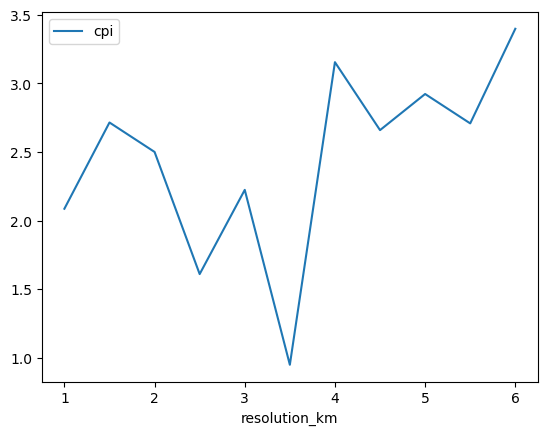

In [20]:
df_metric_final.plot(x = 'resolution_km', y = 'cpi', kind = 'line')
plt.show()